# Passaggio 6: backtest delle versioni A, B e C su tutte le versioni di risultati (solo train)

**Obiettivo.** Rispondere a due domande. La prima: i 7.4 punti base lordi per trade del Passaggio 4 sopravvivono ai costi di trading? La seconda: l'agente di notizie migliora la strategia? Il motore è nel modulo [backtest.py](backtest.py); parte dai trade di `signals_15pairs_v2_train.csv` ([03_segnali.ipynb](03_segnali.ipynb)) e applica versione, costi e capitale.

**Le tre versioni**
- **A**: tutti i segnali entrano, senza agente.
- **B**: l'agente può solo bloccare un segnale.
- **C**: l'agente può bloccare oppure seguire la notizia, cioè entrare nella direzione opposta alla A, scommettendo che lo spread continui ad allargarsi.

**Le versioni di risultati** (i set di decisioni, `VERSIONS` in `backtest.py`): l'agente Spark X2.6 4B con le notizie delle 24 ore prima (principale) e delle 6 ore prima, una baseline senza modello che conta le parole positive e negative del lessico Loughran-McDonald, e due set parziali sui 40 segnali classificati a mano: l'agente con il ragionamento acceso e la classificazione del gruppo.

**Regole fissate prima di guardare i risultati**
- importo fisso di 10.000 dollari per gamba, uguale sulle due gambe, senza leva; tutto chiuso a fine giornata;
- un trade ha 4 operazioni (apertura e chiusura di due gambe): costo del trade = 4 x costo per operazione;
- per le 15 coppie il docente ha indicato di non considerare i costi: **lo scenario principale è il costo 0**; 2, 5 e 10 punti base per operazione sono l'analisi di sensibilità, con 5 come scenario realistico (decisione di Bea);
- capitale del portafoglio = 20.000 dollari per coppia (15 coppie = 300.000), i giorni senza trade valgono 0;
- Sharpe senza tasso privo di rischio, perché i trade durano ore e i dati sono 3 mesi;
- versione C: il trade che segue la notizia apre alla stessa barra della A, nella direzione della notizia, ed esce al primo tra rientro dello spread (z torna a 0: la notizia aveva torto), 90 minuti e fine giornata; nessuno stop oltre al rientro;
- **il test (dal 17 settembre) non si legge**: il motore rifiuta trade dopo il 16 settembre.

Limite da ricordare: i risultati sono sul train, su cui sono stati scelti i parametri del segnale e le regole dell'agente, quindi sono ottimistici.

## 1. Dati e controllo di coerenza

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, next(str(p) for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()))   # cartella del progetto: rende importabile src

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import RESULTS
from src.backtest import (load_trades, trading_days, load_version, apply_version, random_decisions, add_costs, daily_pnl, summary,
                          breakeven_cost, by_cost, by_group, entry_window, version_trades, compare_versions, blocked_vs_random,
                          save_results, VERSIONS, COST_SCENARIOS, MAIN_COST, OPERATIONS_PER_TRADE)

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 200
trades = load_trades()
days = trading_days()
print(len(trades), "trade,", len(days), "giorni di train,", trades.pair.nunique(), "coppie")

# A costo zero il motore deve riprodurre i numeri del Passaggio 4: 973 trade, 7.4 bps lordi
a0 = add_costs(apply_version(trades, "A"), 0)
assert len(a0) == 973 and round(a0.gross_bps.mean(), 1) == 7.4, "i numeri non tornano con il Passaggio 4"
assert np.allclose(a0.net_bps, a0.gross_bps)
# Un agente che non blocca niente deve dare esattamente la A
assert apply_version(trades, "B", random_decisions(trades, p_block=0)).equals(apply_version(trades, "A"))
print("controllo ok: 973 trade, guadagno lordo medio", round(a0.gross_bps.mean(), 2), "bps")

973 trade, 64 giorni di train, 15 coppie
controllo ok: 973 trade, guadagno lordo medio 7.44 bps


## 2. Versione A per scenario di costo

In [2]:
A = apply_version(trades, "A")
table = by_cost(A, days)
table[["trade", "gross_bps", "net_bps", "se_bps", "win_rate", "profit_factor", "pnl_usd", "total_return", "sharpe", "max_drawdown"]]

,trade,gross_bps,net_bps,se_bps,win_rate,profit_factor,pnl_usd,total_return,sharpe,max_drawdown
cost_bps_per_operation,,,,,,,,,,
0,973.00,7.44,7.44,2.03,0.60,1.45,"7,239.43",0.02,8.13,-0.00
2,973.00,7.44,-0.56,2.03,0.53,0.97,-544.57,-0.00,-0.62,-0.01
5,973.00,7.44,-12.56,2.03,0.39,0.52,"-12,220.57",-0.04,-13.55,-0.04
10,973.00,7.44,-32.56,2.03,0.20,0.20,"-31,680.57",-0.11,-31.28,-0.11


In [3]:
be = breakeven_cost(A)
print(f"Costo di pareggio: {be:.2f} bps per operazione ({OPERATIONS_PER_TRADE * be:.2f} bps per trade).")
print(f"Scenario realistico ({MAIN_COST} bps): costo {OPERATIONS_PER_TRADE * MAIN_COST} bps per trade contro {A.gross_bps.mean():.2f} bps lordi.")

Costo di pareggio: 1.86 bps per operazione (7.44 bps per trade).
Scenario realistico (5 bps): costo 20 bps per trade contro 7.44 bps lordi.


## 3. Da dove viene il guadagno della A (scenario realistico)

In [4]:
by_group(A, "pair")

,trade,gross_bps,net_bps,se_bps,win_rate
pair,,,,,
BAC-C,71,3.42,-16.58,6.17,0.42
CL-PG,63,6.61,-13.39,4.73,0.40
COP-EOG,61,-0.99,-20.99,5.33,0.34
CRM-WDAY,60,28.19,8.19,19.11,0.52
CSX-UNP,61,6.81,-13.19,4.16,0.38
DHR-TMO,62,6.59,-13.41,6.46,0.45
ELV-UNH,59,10.76,-9.24,7.36,0.44
GS-MS,72,9.62,-10.38,4.08,0.39
HD-LOW,65,4.39,-15.61,4.13,0.37


In [5]:
by_group(A, entry_window(A))

,trade,gross_bps,net_bps,se_bps,win_rate
finestra,,,,,
apertura (15-30 min),457,11.43,-8.57,3.16,0.46
dopo i 30 min,516,3.90,-16.10,2.60,0.34


In [6]:
by_group(A, "exit_reason")

,trade,gross_bps,net_bps,se_bps,win_rate
exit_reason,,,,,
fine_giornata,56,0.26,-19.74,18.24,0.09
rientro,464,38.79,18.79,1.39,0.71
stop,31,-32.10,-52.10,6.77,0.06
tempo,422,-23.17,-43.17,2.92,0.11


Il costo di pareggio per le sole entrate dopo i 30 minuti (le altre sono il rientro del gap della notte, vedi Passaggio 4):

In [7]:
w = entry_window(A)
for name, sub in A.groupby(w):
    print(f"{name}: {len(sub)} trade, lordo {sub.gross_bps.mean():.2f} bps, costo di pareggio {breakeven_cost(sub):.2f} bps per operazione")

apertura (15-30 min): 457 trade, lordo 11.43 bps, costo di pareggio 2.86 bps per operazione
dopo i 30 min: 516 trade, lordo 3.90 bps, costo di pareggio 0.98 bps per operazione


## 4. Le versioni di risultati

Ogni set di decisioni viene portato allo stesso formato da `load_version`: per ogni segnale, la decisione della B (`entra` o `blocca`), quella della C (`entra`, `blocca` o `segui`) e la direzione da seguire. Per la baseline a lessico, `flat` vuol dire bloccare e `solo_A`/`solo_B` con `long`/`short` vuol dire seguire la notizia su quel titolo: la C del lessico è simulata con la coppia coperta (long su un titolo, short sull'altro), come quella dell'agente. La classificazione a mano non ha la direzione da seguire, quindi entra solo nella B.

In [8]:
pd.DataFrame([
    dict(versione=name, segnali=len(d := load_version(name)), completa=v["complete"],
         B_blocca=(d.decision == "blocca").sum(), C_blocca=(d.decision_C == "blocca").sum(), C_segui=(d.decision_C == "segui").sum(),
         descrizione=v["label"])
    for name, v in VERSIONS.items()
]).set_index("versione")

,segnali,completa,B_blocca,C_blocca,C_segui,descrizione
versione,,,,,,
spark_24h,973,True,48,35,13,"Agente Spark X2.6 4B, notizie delle 24 ore pri..."
spark_6h,973,True,25,16,9,"Agente Spark X2.6 4B, notizie delle 6 ore prim..."
lessico,973,True,166,105,61,Baseline senza modello: parole positive e nega...
spark_24h_ragiona,40,False,5,3,2,"Agente Spark X2.6 4B, 24 ore, ragionamento acc..."
mano,40,False,5,4,1,"Classificazione a mano del gruppo, con la stes..."


## 5. A, B e C sui 973 segnali

Una riga per set di decisioni, versione e costo per operazione. `trade_esclusi` è il numero di segnali bloccati. La A è la stessa per tutti i set e compare una volta sola.

In [9]:
COMPLETE = [n for n, v in VERSIONS.items() if v["complete"]]
cmp = compare_versions(trades, days, COMPLETE, costs=(0, MAIN_COST))

# controlli: la B toglie esattamente i segnali bloccati, la C tiene gli 'entra' e aggiunge i 'segui'
for name in COMPLETE:
    d = load_version(name)
    assert cmp.loc[(name, "B", 973, 0), "trade"] == (d.decision == "entra").sum()
    assert cmp.loc[(name, "C", 973, 0), "trade"] == d.decision_C.isin(["entra", "segui"]).sum()

cmp[["trade_esclusi", "trade", "gross_bps", "net_bps", "se_bps", "win_rate", "profit_factor", "pnl_usd", "total_return", "sharpe", "max_drawdown"]]

trade_esclusi  trade  gross_bps  net_bps  se_bps  win_rate  profit_factor    pnl_usd  total_return  sharpe  max_drawdown
decisioni     versione segnali cost_bps                                                                                                                          
nessun agente A        973     0                     0    973       7.44     7.44    2.03      0.60           1.45   7,239.43          0.02    8.13         -0.00
                               5                     0    973       7.44   -12.56    2.03      0.39           0.52 -12,220.57         -0.04  -13.55         -0.04
spark_24h     B        973     0                    48    925       6.38     6.38    1.72      0.60           1.39   5,905.33          0.02    8.06         -0.00
                               5                    48    925       6.38   -13.62    1.72      0.39           0.48 -12,594.67         -0.04  -16.30         -0.04
              C        973     0                    35    938       4.15     4.15    2.20      0.60           1.23   3,891.61          0.01    3.63         -0.00
                               5                    35    938       4.15   -15.85    2.20      0.39           0.44 -14,868.39         -0.05  -13.21         -0.05
spark_6h      B        973     0                    25    948       6.14     6.14    1.69      0.60           1.38   5,818.96          0.02    7.95         -0.00
                               5                    25    948       6.14   -13.86    1.69      0.39           0.47 -13,141.04         -0.04  -16.96         -0.04
              C        973     0                    16    957       3.97     3.97    2.17      0.60           1.21   3,795.35          0.01    3.45         -0.00
                               5                    16    957       3.97   -16.03    2.17      0.39           0.44 -15,344.65         -0.05  -13.16         -0.05
lessico       B        973     0                   166    807       7.08     7.08    2.15      0.60           1.44   5,712.35          0.02    6.95         -0.00
                               5                   166    807       7.08   -12.92    2.15      0.39           0.50 -10,427.65         -0.03  -12.72         -0.03
              C        973     0                   105    868       5.46     5.46    2.05      0.57           1.33   4,737.54          0.02    5.41         -0.00
                               5                   105    868       5.46   -14.54    2.05      0.38           0.46 -12,622.46         -0.04  -14.68         -0.04

In [10]:
# Differenza rispetto alla A, in dollari guadagnati sul train e in punti base per trade
a_row = cmp.xs("nessun agente", level="decisioni")
delta = []
for (dec, ver, seg, c), r in cmp.drop(index="nessun agente", level="decisioni").iterrows():
    base = a_row.loc[("A", seg, c)]
    delta.append(dict(decisioni=dec, versione=ver, cost_bps=c, delta_pnl_usd=r.pnl_usd - base.pnl_usd,
                      delta_net_bps=r.net_bps - base.net_bps, delta_sharpe=r.sharpe - base.sharpe))
delta = pd.DataFrame(delta).set_index(["decisioni", "versione", "cost_bps"])
delta

delta_pnl_usd  delta_net_bps  delta_sharpe
decisioni versione cost_bps                                            
spark_24h B        0             -1,334.10          -1.06         -0.07
                   5               -374.10          -1.06         -2.75
          C        0             -3,347.82          -3.29         -4.50
                   5             -2,647.82          -3.29          0.34
spark_6h  B        0             -1,420.47          -1.30         -0.17
                   5               -920.47          -1.30         -3.41
          C        0             -3,444.08          -3.47         -4.68
                   5             -3,124.08          -3.47          0.39
lessico   B        0             -1,527.08          -0.36         -1.18
                   5              1,792.92          -0.36          0.83
          C        0             -2,501.88          -1.98         -2.72
                   5               -401.88          -1.98         -1.14

## 6. Che cosa blocca ogni versione: meglio del caso?

La B migliora la A solo se i trade bloccati sono peggiori della media. Il confronto: guadagno lordo medio dei trade bloccati, contro 5.000 blocchi casuali dello stesso numero di trade. `p_value` è la quota di blocchi casuali che tolgono trade ancora peggiori: sotto 0,05 l'agente sceglie meglio del caso, vicino a 1 toglie proprio i trade migliori. Il costo è uguale per ogni trade, quindi il confronto sul lordo vale per qualsiasi scenario di costo.

In [11]:
blocks = pd.DataFrame({name: blocked_vs_random(trades, load_version(name)) for name in COMPLETE}).T
blocks

,segnali,bloccati,lordo_bloccati_bps,lordo_tenuti_bps,lordo_tutti_bps,lordo_bloccati_a_caso_bps,p_value
spark_24h,973.00,48.00,27.79,6.38,7.44,7.31,0.97
spark_6h,973.00,25.00,56.82,6.14,7.44,7.10,1.00
lessico,973.00,166.00,9.20,7.08,7.44,7.49,0.67


In [12]:
# I trade bloccati dall'agente principale: categoria della notizia e guadagno che il blocco ha tolto
raw24 = pd.read_csv(VERSIONS["spark_24h"]["path"])
blocked24 = trades.merge(raw24[["signal_id", "decision", "ticker", "reason", "structural_on_moved_leg"]], on="signal_id")
blocked24 = blocked24[blocked24.decision == "blocca"]
print(len(blocked24), "trade bloccati;", (blocked24.gross_bps > 0).sum(), "avrebbero guadagnato al lordo")
print("per motivo di uscita (costo 0):")
print(by_group(blocked24, "exit_reason", cost_bps=0))
print("\nper coppia (costo 0):")
print(by_group(blocked24, "pair", cost_bps=0))

48 trade bloccati; 27 avrebbero guadagnato al lordo
per motivo di uscita (costo 0):
               trade  gross_bps  net_bps  se_bps  win_rate
exit_reason                                               
fine_giornata      1     984.55   984.55     NaN      1.00
rientro           23      29.46    29.46    4.01      1.00
stop               3       6.61     6.61   33.96      0.33
tempo             21     -16.56   -16.56   30.32      0.10

per coppia (costo 0):
          trade  gross_bps  net_bps  se_bps  win_rate
pair                                                 
BAC-C         5       3.08     3.08   21.07      0.80
CL-PG         2     -65.82   -65.82   40.16      0.00
COP-EOG       2      28.95    28.95   26.88      1.00
CRM-WDAY      5     193.72   193.72  198.81      0.40
DHR-TMO       2     -27.96   -27.96   72.24      0.50
ELV-UNH       2      25.73    25.73   16.04      1.00
GS-MS         9       1.24     1.24    8.20      0.56
HD-LOW        3      -7.89    -7.89   17.59      0.33

In [13]:
# I 10 trade bloccati con il guadagno lordo più grande in valore assoluto, con il motivo dell'agente
cols = ["signal_id", "pair", "t_signal", "ticker", "exit_reason", "gross_bps", "reason"]
with pd.option_context("display.max_colwidth", 90):
    display(blocked24.assign(abs_g=blocked24.gross_bps.abs()).nlargest(10, "abs_g")[cols].reset_index(drop=True))

,signal_id,pair,t_signal,ticker,exit_reason,gross_bps,reason
0,639,CRM-WDAY,2026-08-13 14:49:00,WDAY,fine_giornata,984.55,"L'item informa che Company B è in trattativa per essere acquistata da Silver Lake, il ..."
1,297,PYPL-XYZ,2026-07-15 09:45:00,PYPL,tempo,563.88,L'oggetto è una proposta di acquisto di $53 miliardi tra Stripe e Advent per Company A...
2,441,KO-PEP,2026-07-28 09:45:00,KO,tempo,-138.33,L'item riferisce a un annuncio del CFO di Company A che ha influito sul comportamento ...
3,538,CL-PG,2026-08-05 10:00:00,PG,tempo,-105.97,"L'item informa una acquisizione di Company B, il che introduce un fattore strutturale ..."
4,528,DHR-TMO,2026-08-04 11:38:00,DHR,tempo,-100.20,L'annuncio di nomina di Julie Sawyer Montgomery come presidente e CEO di Company A è u...
5,901,PYPL-XYZ,2026-09-09 09:45:00,XYZ,rientro,82.48,L'azienda ha presentato una richiesta all'Office of the Comptroller of Currency per is...
6,630,BAC-C,2026-08-13 10:21:00,BAC,tempo,-80.58,L'annuncio di un acquisto di una parte significativa del capitale di Jio Credit da par...
7,281,JPM-WFC,2026-07-14 09:46:00,JPM,tempo,-79.04,"La notizia riguarda il CEO di Company A, che afferma che il percorso della successione..."
8,118,JPM-WFC,2026-06-26 10:45:00,JPM,tempo,-78.23,Il testo descrive un agito di leadership in Company A e la possibilità di sostituzione...
9,637,CRM-WDAY,2026-08-13 14:38:00,WDAY,stop,72.05,"L'item informa che Company B è in trattativa per essere acquistata da Silver Lake, il ..."


In [14]:
# Senza i casi estremi: il risultato della B dipende da pochi trade?
for name in COMPLETE:
    m = trades.merge(load_version(name)[["signal_id", "decision"]], on="signal_id")
    b = m[m.decision != "entra"]
    print(f"{name}: {len(b)} bloccati, lordo medio {b.gross_bps.mean():.1f} bps, mediana {b.gross_bps.median():.1f} bps, "
          f"senza i 3 più grandi {b.gross_bps.sort_values().iloc[:-3].mean():.1f} bps")

spark_24h: 48 bloccati, lordo medio 27.8 bps, mediana 7.6 bps, senza i 3 più grandi -6.6 bps
spark_6h: 25 bloccati, lordo medio 56.8 bps, mediana 13.1 bps, senza i 3 più grandi -9.1 bps
lessico: 166 bloccati, lordo medio 9.2 bps, mediana 13.1 bps, senza i 3 più grandi 3.9 bps


## 7. Versione C: i trade che seguono la notizia

Per ogni segnale `segui`, il guadagno del trade che segue la notizia contro quello che avrebbe fatto la A sullo stesso segnale. I trade `segui` sono pochi (13 per l'agente principale): sono casi da leggere uno per uno, non una statistica.

In [15]:
rows = []
for name in COMPLETE:
    C = apply_version(trades, "C", load_version(name))
    f = C[C.c_kind.str.startswith("segui")].merge(trades[["signal_id", "gross_bps", "exit_reason"]], on="signal_id", suffixes=("", "_A"))
    rows.append(dict(versione=name, segui=len(f), lordo_C_bps=f.gross_bps.mean(), lordo_A_stessi_bps=f.gross_bps_A.mean(),
                     somma_C_bps=f.gross_bps.sum(), somma_A_stessi_bps=f.gross_bps_A.sum(), C_guadagna=(f.gross_bps > 0).sum(),
                     A_guadagna=(f.gross_bps_A > 0).sum()))
pd.DataFrame(rows).set_index("versione")

,segui,lordo_C_bps,lordo_A_stessi_bps,somma_C_bps,somma_A_stessi_bps,C_guadagna,A_guadagna
versione,,,,,,,
spark_24h,13,-154.90,125.69,"-2,013.72","1,633.91",4,9
spark_6h,9,-224.85,182.64,"-2,023.61","1,643.80",2,7
lessico,61,-15.98,15.98,-974.81,974.81,17,44


In [16]:
C24 = apply_version(trades, "C", load_version("spark_24h"))
f24 = C24[C24.c_kind.str.startswith("segui")].merge(trades[["signal_id", "direction", "gross_bps", "exit_reason"]], on="signal_id", suffixes=("_C", "_A"))
assert (f24.direction_C != f24.direction_A).all() and (f24.minutes_in_trade <= 90).all()
f24[["signal_id", "pair", "t_signal", "direction_A", "exit_reason_A", "gross_bps_A", "direction_C", "exit_reason_C", "gross_bps_C", "minutes_in_trade"]]

,signal_id,pair,t_signal,direction_A,exit_reason_A,gross_bps_A,direction_C,exit_reason_C,gross_bps_C,minutes_in_trade
0,213,JPM-WFC,2026-07-08 09:46:00,short JPM / long WFC,rientro,15.37,long JPM / short WFC,rientro,-15.37,7.00
1,219,JPM-WFC,2026-07-08 10:46:00,short JPM / long WFC,rientro,23.70,long JPM / short WFC,rientro,-23.70,71.00
2,235,BAC-C,2026-07-09 11:09:00,short BAC / long C,rientro,27.37,long BAC / short C,rientro,-27.37,71.00
3,297,PYPL-XYZ,2026-07-15 09:45:00,short PYPL / long XYZ,tempo,563.88,long PYPL / short XYZ,tempo,-563.88,90.00
4,369,GS-MS,2026-07-22 09:57:00,short GS / long MS,rientro,25.40,long GS / short MS,rientro,-25.40,10.00
5,381,GS-MS,2026-07-22 14:58:00,short GS / long MS,rientro,5.49,long GS / short MS,rientro,-5.49,45.00
6,523,MA-V,2026-08-04 09:45:00,long MA / short V,tempo,-29.84,short MA / long V,tempo,29.84,90.00
7,631,HD-LOW,2026-08-13 10:23:00,long HD / short LOW,tempo,-12.92,short HD / long LOW,tempo,12.92,90.00
8,637,CRM-WDAY,2026-08-13 14:38:00,long CRM / short WDAY,stop,72.05,short CRM / long WDAY,fine_giornata,204.54,80.00
9,638,CRM-WDAY,2026-08-13 14:44:00,long CRM / short WDAY,stop,-41.87,short CRM / long WDAY,fine_giornata,-614.54,74.00


In [17]:
# Un trade 'segui' può restare aperto quando arriva il segnale successivo della stessa coppia (nella A ogni coppia ha un trade
# aperto alla volta). Quanti casi?
def overlaps(C):
    C = C.sort_values("t_entry")
    prev_exit = C.groupby("pair").t_exit.shift()
    return int((C.t_entry < prev_exit).sum())

print({name: overlaps(apply_version(trades, "C", load_version(name))) for name in COMPLETE})

{'spark_24h': 2, 'spark_6h': 2, 'lessico': 0}


## 8. Versioni parziali sui 40 segnali del campione classificato a mano

Sugli stessi 40 segnali: la A, la B dell'agente principale, la B con il ragionamento acceso e la B ricavata dalla classificazione a mano del gruppo (con la stessa regola dell'agente). Su 40 trade la differenza tra le versioni è di pochi trade: serve a vedere se l'agente blocca gli stessi segnali del gruppo, non a misurare un guadagno.

In [18]:
sample_ids = load_version("mano").signal_id
on_sample = trades[trades.signal_id.isin(sample_ids)]
PARTIAL = ["spark_24h", "spark_24h_ragiona", "mano"]
rows = [dict(decisioni="nessun agente", versione="A") | summary(on_sample)]
for name in PARTIAL:
    b = apply_version(on_sample, "B", load_version(name))
    rows.append(dict(decisioni=name, versione="B") | summary(b))
sample_cmp = pd.DataFrame(rows).set_index(["decisioni", "versione"])
sample_cmp[["trade", "gross_bps", "se_bps", "win_rate", "profit_factor"]]

,,trade,gross_bps,se_bps,win_rate,profit_factor
decisioni,versione,,,,,
nessun agente,A,40,13.95,8.03,0.62,2.10
spark_24h,B,35,13.39,8.18,0.60,2.15
spark_24h_ragiona,B,35,13.39,8.18,0.60,2.15
mano,B,35,13.92,8.29,0.60,2.19


In [19]:
# Su quali segnali l'agente e il gruppo decidono in modo diverso?
dec = pd.DataFrame({name: load_version(name).set_index("signal_id").decision for name in PARTIAL}).loc[sample_ids]
dec = dec.join(trades.set_index("signal_id")[["pair", "gross_bps"]])
print("accordo con il gruppo:", {n: f"{(dec[n] == dec.mano).mean():.0%}" for n in PARTIAL if n != "mano"})
dec[(dec.spark_24h != dec.mano) | (dec.spark_24h_ragiona != dec.mano)]

accordo con il gruppo: {'spark_24h': '95%', 'spark_24h_ragiona': '95%'}


,spark_24h,spark_24h_ragiona,mano,pair,gross_bps
signal_id,,,,,
489,entra,entra,blocca,HD-LOW,64.10
901,blocca,blocca,entra,PYPL-XYZ,82.48


## 9. Curve di capitale

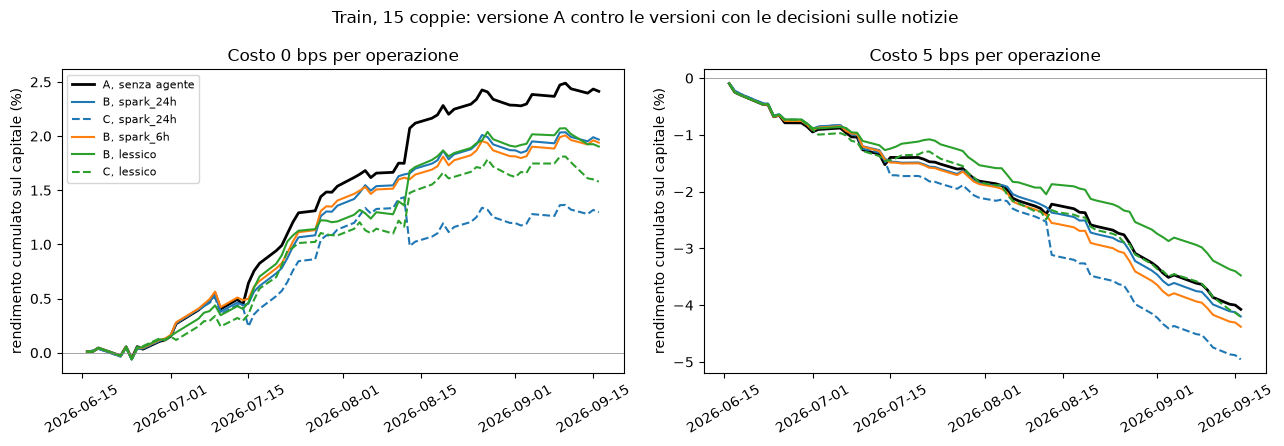

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)
for ax, c in zip(axes, (0, MAIN_COST)):
    for name, letter, style in [("spark_24h", "A", dict(color="black", lw=2)), ("spark_24h", "B", dict(color="tab:blue")),
                                ("spark_24h", "C", dict(color="tab:blue", ls="--")), ("spark_6h", "B", dict(color="tab:orange")),
                                ("lessico", "B", dict(color="tab:green")), ("lessico", "C", dict(color="tab:green", ls="--"))]:
        t = version_trades(trades, name, (letter,))[letter]
        d = daily_pnl(add_costs(t, c), days)
        ax.plot(d.index, d.equity * 100, label="A, senza agente" if letter == "A" else f"{letter}, {name}", **style)
    ax.axhline(0, color="grey", lw=0.5)
    ax.set_title(f"Costo {c} bps per operazione")
    ax.set_ylabel("rendimento cumulato sul capitale (%)")
    ax.tick_params(axis="x", rotation=30)
axes[0].legend(fontsize=8)
fig.suptitle("Train, 15 coppie: versione A contro le versioni con le decisioni sulle notizie")
fig.tight_layout()
fig.savefig(RESULTS / "curve_capitale.png", dpi=120)
plt.show()

## 10. Salvataggio in `Results/`

Le tabelle di questo notebook e i trade di ogni versione vanno in `Results/`, che è su git: chi non ha i dati può leggere i risultati senza rieseguire niente. Il resoconto per chi non conosce la finanza è in [Results/RESOCONTO.md](../Results/RESOCONTO.md).

In [21]:
tables = {"confronto_versioni": cmp, "differenza_dalla_A": delta, "bloccati_contro_caso": blocks, "confronto_campione_40": sample_cmp,
          "A_per_costo": table, "A_per_coppia": by_group(A, "pair")}
for name in COMPLETE:
    for letter, t in version_trades(trades, name).items():
        if letter != "A":
            tables[f"{name}/trades_{letter}"] = t
tables["trades_A"] = A
for p in save_results(tables):
    print(p.relative_to(RESULTS.parent))

Results/confronto_versioni.csv
Results/differenza_dalla_A.csv
Results/bloccati_contro_caso.csv
Results/confronto_campione_40.csv
Results/A_per_costo.csv
Results/A_per_coppia.csv
Results/spark_24h/trades_B.csv
Results/spark_24h/trades_C.csv
Results/spark_6h/trades_B.csv
Results/spark_6h/trades_C.csv
Results/lessico/trades_B.csv
Results/lessico/trades_C.csv
Results/trades_A.csv


## 11. Cosa ci dicono i risultati

I numeri sono quelli delle tabelle qui sopra (train, 15 coppie, 973 segnali). Costo 0 è lo scenario principale.

**Versione A.** 973 trade, 7,44 bps lordi per trade (errore standard 2,03): +7.239 dollari su 300.000 di capitale in 64 giorni (+2,4%). Con i costi perde: il pareggio è a 1,86 bps per operazione; a 5 bps il trade medio perde 12,56 bps e il train chiude a -12.221 dollari (-4,1%).

**Versione B: l'agente blocca trade migliori della media, non peggiori.** L'agente principale (24 ore) blocca 48 segnali, e quei trade avevano un guadagno lordo medio di 27,8 bps, quasi quattro volte la media di 7,4. Bloccando 48 trade a caso si toglierebbero in media 7,3 bps: il 97% dei blocchi casuali fa meglio dell'agente (p = 0,97). A costo 0 la B guadagna 1.334 dollari meno della A (6,38 contro 7,44 bps per trade). Con la finestra di 6 ore succede lo stesso, in modo più netto (25 blocchi, 56,8 bps medi, p = 1,00). La baseline a lessico blocca 166 segnali con 9,2 bps medi (p = 0,67): non si distingue da un blocco a caso.

Il motivo è nei trade bloccati: 23 dei 48 sono usciti per rientro, con +29,5 bps medi. Una notizia vera su un solo titolo produce gli allargamenti più grandi, e in questo periodo molti di questi sono rientrati lo stesso nella giornata. Il risultato però dipende da pochi casi: la mediana dei trade bloccati è 7,6 bps, e senza i 3 trade più grandi (CRM-WDAY del 13 agosto, con la notizia di Silver Lake che tratta per comprare Workday, e due segnali di PYPL-XYZ) la media scende a -6,6 bps. Quindi non c'è prova che bloccare sulle notizie aiuti, e c'è un'indicazione che tolga alcuni dei trade migliori.

A 5 bps la B del lessico perde 1.793 dollari meno della A. Non vuol dire che scelga bene: a quel costo ogni trade perde in media 12,6 bps, quindi qualsiasi blocco fa risparmiare costi, e 166 blocchi a caso darebbero lo stesso effetto.

**Versione C: seguire la notizia peggiora ancora.** I 13 trade `segui` dell'agente principale perdono in media 154,9 bps, mentre la A sugli stessi segnali guadagnava 125,7 bps: a costo 0 la C fa 3.348 dollari meno della A. Il trade che segue la notizia è quasi lo specchio della A: quando la A esce per rientro o per tempo, la C esce allo stesso minuto con il guadagno opposto; cambia solo quando la A esce per stop, perché la C non ha stop. Pesano soprattutto i tre segnali di CRM-WDAY del 13 agosto. Per il lessico (61 `segui`): -16,0 bps medi contro +16,0 della A.

**Campione dei 40 segnali.** Agente e gruppo prendono la stessa decisione su 38 segnali su 40 (95%); con il ragionamento acceso le decisioni non cambiano. I due disaccordi sono il segnale 489 (HD-LOW, il gruppo blocca, la A guadagnava 64 bps) e il 901 (PYPL-XYZ, l'agente blocca, la A guadagnava 82 bps).

**In sintesi.** Sul train la regola "notizia strutturale su un solo titolo, quindi non entrare" non migliora la strategia con nessuno dei set di decisioni, e seguire la notizia la peggiora. Prima di aprire il test bisogna decidere quale versione portarci, con regole bloccate: scegliere adesso la variante che sul train va meglio sarebbe adattarsi ai dati.

**Limiti.** Risultati sul train, su cui sono stati scelti segnale e regole dell'agente. Pochi blocchi (25-166) e pochissimi `segui` (9-61): le differenze dipendono da una manciata di trade e soprattutto da un giorno (13 agosto). La regola della C (niente stop, uscita a 90 minuti) è nostra; in 2 casi un trade `segui` resta aperto mentre arriva il segnale successivo della stessa coppia, che quindi usa due volte il capitale della coppia. La baseline a lessico è un file già pronto: il codice che lo produce non è nel repo. Costi per operazione stimati, nessun costo di prestito dei titoli, una parte dei trade eseguita a un prezzo vecchio (barra riempita). Lo Sharpe è annualizzato su 64 giorni con rendimenti giornalieri minuscoli: un valore come 8 non va letto come quello di un fondo. Il modello può conoscere gli eventi del periodo (lookahead), ridotto ma non eliminato dall'anonimizzazione.